# 6. Multiobjetivo: construir alternativas e escolher com critérios

In [1]:
from pathlib import Path
import sys, json, numpy as np
ROOT = Path.cwd().resolve()
if not (ROOT / 'optimization_examples').is_dir():
    ROOT = ROOT.parent  # notebooks opened from codes/notebooks/
if not (ROOT / 'optimization_examples').is_dir():
    raise RuntimeError('Abra o notebook a partir do repositório codes ou codes/notebooks.')
sys.path.insert(0, str(ROOT))
OUT = ROOT / 'results' / 'sequence'
OUT.mkdir(parents=True, exist_ok=True)
def save(name, value):
    (OUT / name).write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')


81 cardápios: uma opção em cada uma das quatro categorias. Três indicadores nutricionais e alvos são inventados, sem unidades clínicas. Adequação = porcentagem desses três alvos atingidos; não diagnóstico de saúde. Fração ultraprocessada = energia fictícia de itens marcados / energia fictícia total. Não representa todo o PNAE.

In [2]:
from optimization_examples.menu_decision import all_menus, frontier, choose_weighted, aspiration
menus = all_menus()
front2 = frontier(menus,2)
front3 = frontier(menus,3)
print('Universo:',len(menus),'Pareto 2D:',len(front2),'Pareto 3D:',len(front3))
print('Melhor adequação:',max(m['adequacy'] for m in menus),'%')
for m in front3: print(m['foods'],'R$',m['cost'],'adequação',round(m['adequacy'],2),'%','UP',m['ultra'],'%')

Universo: 81 Pareto 2D: 4 Pareto 3D: 6
Melhor adequação: 66.66666666666666 %
['arroz', 'feijao', 'ovo', 'banana'] R$ 4.0 adequação 33.33 % UP 0.0 %
['arroz', 'lentilha', 'frango', 'sobremesa pronta'] R$ 5.6 adequação 66.67 % UP 31.818 %
['macarrao instantaneo', 'feijao', 'ovo', 'banana'] R$ 3.7 adequação 33.33 % UP 28.947 %
['macarrao instantaneo', 'feijao', 'ovo', 'sobremesa pronta'] R$ 3.5 adequação 33.33 % UP 56.818 %
['macarrao instantaneo', 'embutido', 'ovo', 'sobremesa pronta'] R$ 3.3 adequação 0.0 % UP 80.435 %
['arroz integral', 'lentilha', 'ovo', 'verduras'] R$ 6.1 adequação 66.67 % UP 0.0 %


Enumeração de TODOS os 81 menus permite afirmar fronteira exata somente desta grade. NSGA-II pode aproximar frentes maiores, sem garantia de encontrá-las completas. A projeção 2D da frente 3D não necessariamente é a frente ótima de dois objetivos.

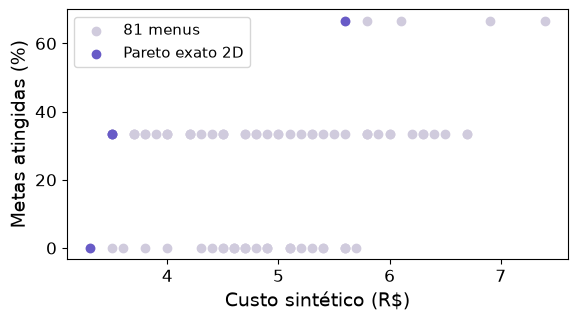

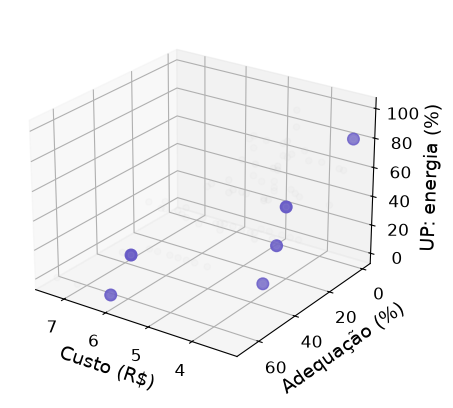

In [3]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':14,'xtick.labelsize':12,'ytick.labelsize':12,'legend.fontsize':11})
fig,ax=plt.subplots(figsize=(6,3.5))
ax.scatter([m['cost'] for m in menus],[m['adequacy'] for m in menus],color='#D0CBDD',label='81 menus')
ax.scatter([m['cost'] for m in front2],[m['adequacy'] for m in front2],color='#685BC7',label='Pareto exato 2D')
ax.set(xlabel='Custo sintético (R$)',ylabel='Metas atingidas (%)'); ax.legend(); fig.tight_layout()
fig.savefig(OUT/'pareto-2d.pdf'); plt.show()
fig=plt.figure(figsize=(6,4)); ax=fig.add_subplot(projection='3d')
ax.scatter([m['cost'] for m in menus],[m['adequacy'] for m in menus],[m['ultra'] for m in menus],color='#CCCCCC',alpha=.3)
ax.scatter([m['cost'] for m in front3],[m['adequacy'] for m in front3],[m['ultra'] for m in front3],color='#685BC7',s=70)
ax.set(xlabel='Custo (R$)',ylabel='Adequação (%)',zlabel='UP: energia (%)'); ax.view_init(24,125)
ax.tick_params(labelsize=12)
fig.subplots_adjust(left=0,right=.90,bottom=.05,top=1); fig.savefig(OUT/'pareto-3d.pdf'); plt.show()

Decisão multicritério: declarar direção, normalizar escalas e justificar preferências. Somamos custo, déficit de adequação e UP normalizados. Os pesos NÃO são uma descoberta científica. Método compensatório: uma vantagem pode compensar uma desvantagem. Regras inegociáveis são filtros, antes da pontuação.

In [4]:
cost_priority = choose_weighted(front3,(.7,.2,.1))
health_priority = choose_weighted(front3,(.1,.7,.2))
rule = aspiration(front3,budget=6,minimum_adequacy=66)
for label,r in [('Priorizar custo',cost_priority),('Priorizar adequação',health_priority)]:
    m=r['menu'];print(label,'pesos',r['weights'],'menu',m['foods'],'custo',m['cost'],'adequação',round(m['adequacy'],2),'UP',m['ultra'])
print('Filtro orçamento <= 6 e adequação >= 66%, depois menor UP:',rule)
save('decision.json',dict(menus=menus,front2=front2,front3=front3,cost_priority=cost_priority,health_priority=health_priority,aspiration=rule))

Priorizar custo pesos [0.7, 0.2, 0.1] menu ['macarrao instantaneo', 'feijao', 'ovo', 'sobremesa pronta'] custo 3.5 adequação 33.33 UP 56.818
Priorizar adequação pesos [0.1, 0.7, 0.2] menu ['arroz integral', 'lentilha', 'ovo', 'verduras'] custo 6.1 adequação 66.67 UP 0.0
Filtro orçamento <= 6 e adequação >= 66%, depois menor UP: {'choice': [0, 1, 1, 2], 'foods': ['arroz', 'lentilha', 'frango', 'sobremesa pronta'], 'cost': 5.6, 'adequacy': 66.66666666666666, 'ultra': 31.818, 'indicators': [18, 18, 7], 'targets_met': 2}
